In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [2]:
df = pd.read_csv("emails.csv")

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (5172, 3002)
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]


In [3]:
print("Column names:")
print(df.columns)

print("\nDataset information:")
df.info()

print("\nMissing values:", df.isnull().sum().sum())

print("\nClass distribution:")
print(df["Prediction"].value_counts())

Column names:
Index(['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou',
       ...
       'connevey', 'jay', 'valued', 'lay', 'infrastructure', 'military',
       'allowing', 'ff', 'dry', 'Prediction'],
      dtype='object', length=3002)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5172 entries, 0 to 5171
Columns: 3002 entries, Email No. to Prediction
dtypes: int64(3001), object(1)
memory usage: 118.5+ MB

Missing values: 0

Class distribution:
Prediction
0    3672
1    1500
Name: count, dtype: int64


In [4]:
X = df.drop(columns=["Email No.", "Prediction"])
y = df["Prediction"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())

Features shape: (5172, 3000)
Target shape: (5172,)

Target classes:
Prediction
0    3672
1    1500
Name: count, dtype: int64


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 4137
Testing samples: 1035


In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


In [7]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)

print("KNN model trained successfully!")

KNN model trained successfully!


In [8]:
cm_knn = confusion_matrix(y_test, y_pred_knn, labels=[0, 1])

accuracy_knn = accuracy_score(y_test, y_pred_knn)
error_knn = 1 - accuracy_knn
precision_knn = precision_score(y_test, y_pred_knn, zero_division=0)
recall_knn = recall_score(y_test, y_pred_knn, zero_division=0)
f1_knn = f1_score(y_test, y_pred_knn, zero_division=0)

print("KNN CONFUSION MATRIX")
print(cm_knn)

print("\nKNN PERFORMANCE")
print("Accuracy  :", round(accuracy_knn * 100, 2), "%")
print("Error Rate:", round(error_knn * 100, 2), "%")
print("Precision :", round(precision_knn, 4))
print("Recall    :", round(recall_knn, 4))
print("F1-Score  :", round(f1_knn, 4))

KNN CONFUSION MATRIX
[[576 159]
 [ 13 287]]

KNN PERFORMANCE
Accuracy  : 83.38 %
Error Rate: 16.62 %
Precision : 0.6435
Recall    : 0.9567
F1-Score  : 0.7694


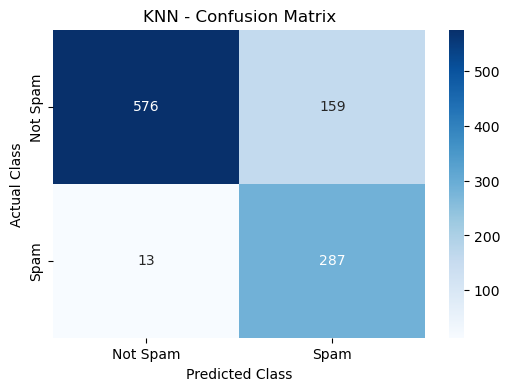

In [9]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Spam", "Spam"],
    yticklabels=["Not Spam", "Spam"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("KNN - Confusion Matrix")
plt.show()

In [10]:
svm = SVC(kernel="linear", random_state=42)

svm.fit(X_train_scaled, y_train)

y_pred_svm = svm.predict(X_test_scaled)

print("SVM model trained successfully!")

SVM model trained successfully!


In [11]:
cm_svm = confusion_matrix(y_test, y_pred_svm, labels=[0, 1])

accuracy_svm = accuracy_score(y_test, y_pred_svm)
error_svm = 1 - accuracy_svm
precision_svm = precision_score(y_test, y_pred_svm, zero_division=0)
recall_svm = recall_score(y_test, y_pred_svm, zero_division=0)
f1_svm = f1_score(y_test, y_pred_svm, zero_division=0)

print("SVM CONFUSION MATRIX")
print(cm_svm)

print("\nSVM PERFORMANCE")
print("Accuracy  :", round(accuracy_svm * 100, 2), "%")
print("Error Rate:", round(error_svm * 100, 2), "%")
print("Precision :", round(precision_svm, 4))
print("Recall    :", round(recall_svm, 4))
print("F1-Score  :", round(f1_svm, 4))

SVM CONFUSION MATRIX
[[709  26]
 [ 25 275]]

SVM PERFORMANCE
Accuracy  : 95.07 %
Error Rate: 4.93 %
Precision : 0.9136
Recall    : 0.9167
F1-Score  : 0.9151


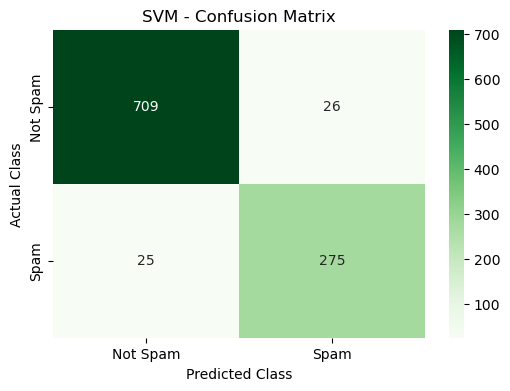

In [12]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Not Spam", "Spam"],
    yticklabels=["Not Spam", "Spam"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("SVM - Confusion Matrix")
plt.show()

In [13]:
print("KNN CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred_knn,
    labels=[0, 1],
    target_names=["Not Spam", "Spam"],
    zero_division=0
))

print("\nSVM CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred_svm,
    labels=[0, 1],
    target_names=["Not Spam", "Spam"],
    zero_division=0
))

KNN CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Not Spam       0.98      0.78      0.87       735
        Spam       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035


SVM CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Not Spam       0.97      0.96      0.97       735
        Spam       0.91      0.92      0.92       300

    accuracy                           0.95      1035
   macro avg       0.94      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035



In [14]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy (%)", "Error Rate (%)", "Precision", "Recall", "F1-Score"],
    "KNN": [
        round(accuracy_knn * 100, 2),
        round(error_knn * 100, 2),
        round(precision_knn, 4),
        round(recall_knn, 4),
        round(f1_knn, 4)
    ],
    "SVM": [
        round(accuracy_svm * 100, 2),
        round(error_svm * 100, 2),
        round(precision_svm, 4),
        round(recall_svm, 4),
        round(f1_svm, 4)
    ]
})

print(comparison.to_string(index=False))

        Metric     KNN     SVM
  Accuracy (%) 83.3800 95.0700
Error Rate (%) 16.6200  4.9300
     Precision  0.6435  0.9136
        Recall  0.9567  0.9167
      F1-Score  0.7694  0.9151


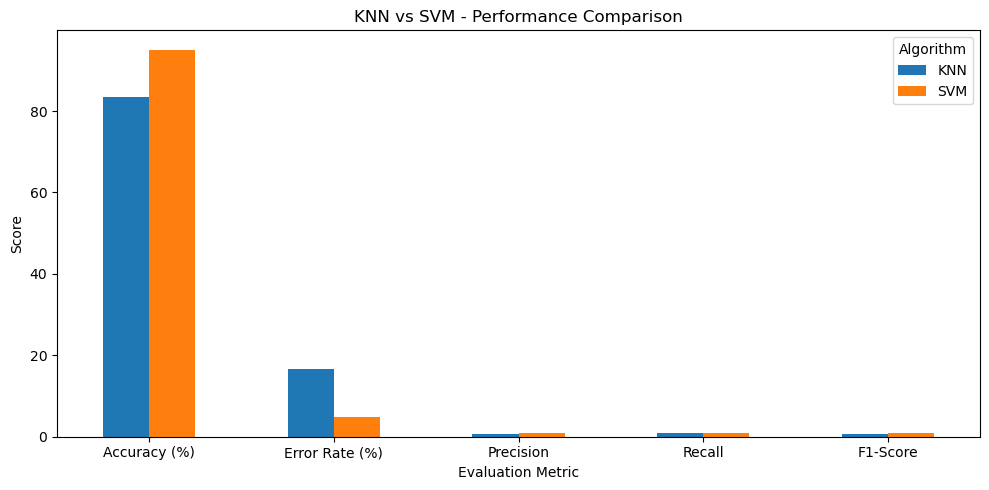

In [15]:
comparison_plot = comparison.set_index("Metric")

comparison_plot.plot(kind="bar", figsize=(10, 5))

plt.title("KNN vs SVM - Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.xticks(rotation=0)
plt.legend(title="Algorithm")
plt.tight_layout()
plt.show()

In [16]:
if f1_svm > f1_knn:
    print("SVM performs better based on the F1-score.")
elif f1_knn > f1_svm:
    print("KNN performs better based on the F1-score.")
else:
    print("Both models have the same F1-score.")

if accuracy_svm > accuracy_knn:
    print("SVM has higher accuracy.")
elif accuracy_knn > accuracy_svm:
    print("KNN has higher accuracy.")
else:
    print("Both models have the same accuracy.")

SVM performs better based on the F1-score.
SVM has higher accuracy.


In [17]:
print("""
CONCLUSION

Email spam detection was implemented using two binary
classification algorithms: K-Nearest Neighbors (KNN) and
Support Vector Machine (SVM).

The models were trained and tested using the emails dataset.
Their performance was evaluated using the confusion matrix,
accuracy, error rate, precision, recall, and F1-score.

The comparison results help identify which algorithm performs
better on the given dataset. The preferred model should have
high precision and recall, a strong F1-score, and a low error rate.
""")


CONCLUSION

Email spam detection was implemented using two binary
classification algorithms: K-Nearest Neighbors (KNN) and
Support Vector Machine (SVM).

The models were trained and tested using the emails dataset.
Their performance was evaluated using the confusion matrix,
accuracy, error rate, precision, recall, and F1-score.

The comparison results help identify which algorithm performs
better on the given dataset. The preferred model should have
high precision and recall, a strong F1-score, and a low error rate.

